# Efficiency versus ΔR in selected generated pT and Lxy bins

Duplicate of `VRE_vs_dR_continous_with_Total`, with two separate selections:
1. **0 ≤ generated pair pT < 5 GeV, 1 ≤ generated Lxy < 5 cm**.
2. **5 ≤ generated pair pT < 10 GeV, 1 ≤ generated Lxy < 5 cm**.

Lxy here is the existing generated `vxy` histogram axis. The same interval selection is applied to numerator and denominator before summing counts across signal samples. Endpoint checks require these ranges to align with stored histogram edges, so partial bins are never approximated.

Keep the input, sample selection, cut, and ΔR binning from the source notebook. Each plot preserves LL, RR, AA, and Total. LR contributes to Total but is not separately drawn by default. **Total = LL + RR + LR**. AA stays separate and is never added to Total. Statistical uncertainty uses numerator/denominator counts after the interval selection.

Use the LPC kernel. No analysis is run by creating this notebook. Only the optional final cell saves files on LPC. Empty denominator bins remain gaps. Horizontal bars show ΔR widths, and connecting lines guide the eye.


In [1]:
from pathlib import Path
import gc
import re
import numpy as np
import matplotlib.pyplot as plt
from coffea import util
from hist.intervals import ratio_uncertainty

LPC_REPO = Path('/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe')
f_sig = LPC_REPO / 'python_analysis/coffea/VertexRes2026/drEff_cont.coffea'
cut = 'cut0'

samples = {10: {0.2: [100]}, 20: {0.2: [100]}, 30: {0.2: [100]}, 40: {0.2: [100]}, 50: {0.2: [100]}, 60: {0.1: [100], 0.2: [100]}, 70: {0.1: [100], 0.2: [100]}, 80: {0.1: [100], 0.2: [100]}, 90: {0.1: [100], 0.2: [100]}, 100: {0.2: [100]}}

expected_dr_edges = np.asarray([
    0, 0.04, 0.08, 0.15, 0.3, 0.4, 0.5, 0.7,
    1, 1.5, 2, 3, 4, 5,
])
print('Input:', f_sig)
print('Samples:', samples)


regions = {
    'pt0to5_lxy1to5': {'pt': (0, 5), 'lxy': (1, 5)},
    'pt5to10_lxy1to5': {'pt': (5, 10), 'lxy': (1, 5)},
    'pt10to20_lxy1to5': {'pt': (10, 20), 'lxy': (1, 5)}
}
print('Requested generated pT/Lxy ranges:', regions)


Input: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/VertexRes2026/drEff_cont.coffea
Samples: {10: {0.2: [100]}, 20: {0.2: [100]}, 30: {0.2: [100]}, 40: {0.2: [100]}, 50: {0.2: [100]}, 60: {0.1: [100], 0.2: [100]}, 70: {0.1: [100], 0.2: [100]}, 80: {0.1: [100], 0.2: [100]}, 90: {0.1: [100], 0.2: [100]}, 100: {0.2: [100]}}
Requested generated pT/Lxy ranges: {'pt0to5_lxy1to5': {'pt': (0, 5), 'lxy': (1, 5)}, 'pt5to10_lxy1to5': {'pt': (5, 10), 'lxy': (1, 5)}, 'pt10to20_lxy1to5': {'pt': (10, 20), 'lxy': (1, 5)}}


In [2]:
# Keep only the five required histograms after loading the file.
print('Loading coffea output...', flush=True)
loaded_output = util.load(str(f_sig))
sig_histo = loaded_output[0]
category_names = ('LL', 'RR', 'LR', 'AA')
histograms = {
    suffix: sig_histo[f'genvtx_pt_vxy_dr_{suffix}']
    for suffix in ('den',) + category_names
}
del sig_histo, loaded_output
gc.collect()
print('Loaded. Retained only the five required histograms.', flush=True)


Loading coffea output...
Loaded. Retained only the five required histograms.


In [3]:
# Select signal points using the same filename convention as plotTools.signalPoint.
# No plotTools import or 2D plotting is needed.
available_samples = list(histograms['den'].axes['samp'])
parsed_samples = []
for name in available_samples:
    match = re.search(r'Mchi-(\d+p\d+)_dMchi-(\d+p\d+)_ctau-(\d+)', name)
    if match is None:
        continue
    mchi = float(match.group(1).replace('p', '.'))
    dmchi = float(match.group(2).replace('p', '.'))
    lifetime = float(match.group(3))
    mass1 = mchi - dmchi / 2
    parsed_samples.append((name, mass1, dmchi / mass1, lifetime))

selected_names = []
for m1, deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            matches = [
                name for name, mass1, splitting, lifetime in parsed_samples
                if np.isclose(mass1, m1, rtol=1e-8, atol=1e-8)
                and np.isclose(splitting, delta, rtol=1e-8, atol=1e-8)
                and lifetime == ctau
            ]
            if len(matches) != 1:
                raise ValueError(f'Expected one sample for {(m1, delta, ctau)}, found {matches}')
            if matches[0] in selected_names:
                raise ValueError(f'Duplicate sample: {matches[0]}')
            selected_names.append(matches[0])
if not selected_names:
    raise ValueError('No signal points selected.')
print('Selected samples:')
for name in selected_names:
    print(' ', name)


# Convert a requested physical interval to exact regular-bin indices.
def interval_slice(edges, low, high):
    left = np.flatnonzero(np.isclose(edges, low, rtol=0, atol=1e-10))
    right = np.flatnonzero(np.isclose(edges, high, rtol=0, atol=1e-10))
    if len(left) != 1 or len(right) != 1 or left[0] >= right[0]:
        raise ValueError(f'Range [{low}, {high}) must align exactly with stored edges {edges}.')
    return slice(int(left[0]), int(right[0]))

counts_by_region = {key: {} for key in regions}
reference_edges = None
for suffix, histogram in histograms.items():
    for sample_index, name in enumerate(selected_names):
        selected = histogram[{'samp': name, 'cut': cut}]
        names = tuple(axis.name for axis in selected.axes)
        expected_names = (f'pt_{suffix}', f'vxy_{suffix}', f'dr_{suffix}')
        if names != expected_names:
            raise ValueError(f'Unexpected axes for {suffix}: {names}')
        current_edges = tuple(np.asarray(axis.edges).copy() for axis in selected.axes)
        if reference_edges is None:
            reference_edges = current_edges
        else:
            for expected, actual in zip(reference_edges, current_edges):
                np.testing.assert_array_equal(expected, actual)
        pt_edges, vxy_edges, source_dr_edges = current_edges
        # Merge existing regular ΔR bins; never interpolate counts.
        # The requested endpoints must cover the same complete source range.
        np.testing.assert_allclose(
            source_dr_edges[[0, -1]], expected_dr_edges[[0, -1]],
            rtol=0, atol=1e-12,
        )
        dr_slices = [
            interval_slice(source_dr_edges, low, high)
            for low, high in zip(expected_dr_edges[:-1], expected_dr_edges[1:])
        ]
        values = selected.values(flow=False)

        for key, region in regions.items():
            pt_slice = interval_slice(pt_edges, *region['pt'])
            lxy_slice = interval_slice(vxy_edges, *region['lxy'])
            # Restrict BOTH pT and Lxy; retain every regular ΔR bin.
            source_counts = values[pt_slice, lxy_slice, :].sum(axis=(0, 1))
            # Sum numerator/denominator counts BEFORE efficiency calculation.
            counts = np.asarray([
                source_counts[group].sum() for group in dr_slices
            ], dtype=float)
            np.testing.assert_allclose(counts.sum(), source_counts.sum())
            if sample_index == 0:
                counts_by_region[key][suffix] = counts.copy()
            else:
                counts_by_region[key][suffix] += counts

pt_edges, vxy_edges, source_dr_edges = reference_edges
dr_edges = expected_dr_edges.copy()
print('Original ΔR edges:', source_dr_edges)
print('Rebinned ΔR edges:', dr_edges)
print('Number of rebinned ΔR intervals:', len(dr_edges) - 1)
print('Count conservation checked for every sample, category, and pT/Lxy selection.')
for key, region in regions.items():
    pt_slice = interval_slice(pt_edges, *region['pt'])
    lxy_slice = interval_slice(vxy_edges, *region['lxy'])
    print(f"{key}: pT [{pt_edges[pt_slice.start]:g}, {pt_edges[pt_slice.stop]:g}) GeV, "
          f"Lxy [{vxy_edges[lxy_slice.start]:g}, {vxy_edges[lxy_slice.stop]:g}) cm")
    print('  Denominator counts by ΔR bin:', counts_by_region[key]['den'])
print('Underflow/overflow excluded. No extra selections beyond these bins and the stored cut.')
del histograms, histogram, selected, values
gc.collect()


Selected samples:
  sig_2022_Mchi-11p0_dMchi-2p0_ctau-100
  sig_2022_Mchi-22p0_dMchi-4p0_ctau-100
  sig_2022_Mchi-33p0_dMchi-6p0_ctau-100
  sig_2022_Mchi-44p0_dMchi-8p0_ctau-100
  sig_2022_Mchi-55p0_dMchi-10p0_ctau-100
  sig_2022_Mchi-63p0_dMchi-6p0_ctau-100
  sig_2022_Mchi-66p0_dMchi-12p0_ctau-100
  sig_2022_Mchi-73p5_dMchi-7p0_ctau-100
  sig_2022_Mchi-77p0_dMchi-14p0_ctau-100
  sig_2022_Mchi-84p0_dMchi-8p0_ctau-100
  sig_2022_Mchi-88p0_dMchi-16p0_ctau-100
  sig_2022_Mchi-94p5_dMchi-9p0_ctau-100
  sig_2022_Mchi-99p0_dMchi-18p0_ctau-100
  sig_2022_Mchi-110p0_dMchi-20p0_ctau-100
Original ΔR edges: [0.   0.01 0.02 0.04 0.06 0.08 0.1  0.15 0.2  0.3  0.4  0.5  0.7  1.
 1.5  2.   3.   4.   5.  ]
Rebinned ΔR edges: [0.   0.04 0.08 0.15 0.3  0.4  0.5  0.7  1.   1.5  2.   3.   4.   5.  ]
Number of rebinned ΔR intervals: 13
Count conservation checked for every sample, category, and pT/Lxy selection.
pt0to5_lxy1to5: pT [0, 5) GeV, Lxy [1, 5) cm
  Denominator counts by ΔR bin: [2.32000e+02 7.3700

0

In [4]:
region_results = {}
for region_key, counts_vs_dr in counts_by_region.items():
    print(f"\nREGION: {region_key}")
    denominator = counts_vs_dr['den']
    if not np.all(np.isfinite(denominator)) or np.any(denominator < 0):
        raise ValueError('Invalid denominator counts.')
    if not np.allclose(denominator, np.round(denominator)):
        raise ValueError('This uncertainty calculation assumes unit-weight event counts.')
    valid = denominator > 0

    # Total contains LL + RR + LR only. AA is NOT included.
    total_components = ('LL', 'RR', 'LR')
    counts_vs_dr['Total'] = sum(counts_vs_dr[c] for c in total_components)
    if np.any(counts_vs_dr['Total'] > denominator):
        raise ValueError('LL + RR + LR counts exceed the common denominator.')

    curve_categories = category_names + ('Total',)
    curves = {}
    for category in curve_categories:
        numerator = counts_vs_dr[category]
        if not np.all(np.isfinite(numerator)) or np.any(numerator < 0) or np.any(numerator > denominator):
            raise ValueError(f'Invalid {category} numerator counts.')
        if not np.allclose(numerator, np.round(numerator)):
            raise ValueError('This uncertainty calculation assumes unit-weight event counts.')
        efficiency = np.divide(numerator, denominator,
                               out=np.full_like(numerator, np.nan), where=valid)
        uncertainty = np.full((2, len(denominator)), np.nan)
        if np.any(valid):
            uncertainty[:, valid] = ratio_uncertainty(numerator[valid], denominator[valid], 'efficiency')
        curves[category] = {'efficiency': efficiency, 'uncertainty': uncertainty}
        print(f'\n{category}: bin interval, numerator / denominator, efficiency')
        for i, (low, high) in enumerate(zip(dr_edges[:-1], dr_edges[1:])):
            if valid[i]:
                print(f'  [{low:g}, {high:g}): {numerator[i]:g} / {denominator[i]:g} '
                      f'= {100 * efficiency[i]:.3f}% '
                      f'(-{100 * uncertainty[0,i]:.3f}, +{100 * uncertainty[1,i]:.3f} percentage points)')
            else:
                print(f'  [{low:g}, {high:g}): denominator 0, omitted')



    # Verify that the count-based total equals the sum of efficiencies.
    summed_efficiency = sum(curves[c]['efficiency'] for c in total_components)
    np.testing.assert_allclose(
        curves['Total']['efficiency'], summed_efficiency, equal_nan=True
    )
    print('\nCheck passed: Total efficiency = LL + RR + LR. AA is excluded.')
    print('TOTAL COUNT CHECK: LL + RR + LR = Total numerator; denominator')
    for i, (low, high) in enumerate(zip(dr_edges[:-1], dr_edges[1:])):
        print(
            f'  [{low:g}, {high:g}): '
            f'{counts_vs_dr["LL"][i]:g} + {counts_vs_dr["RR"][i]:g} + '
            f'{counts_vs_dr["LR"][i]:g} = {counts_vs_dr["Total"][i]:g}; '
            f'denominator = {denominator[i]:g}'
        )
    region_results[region_key] = {"counts": counts_vs_dr, "curves": curves}



REGION: pt0to5_lxy1to5

LL: bin interval, numerator / denominator, efficiency
  [0, 0.04): 1 / 232 = 0.431% (-0.357, +0.984 percentage points)
  [0.04, 0.08): 2 / 737 = 0.271% (-0.175, +0.357 percentage points)
  [0.08, 0.15): 14 / 2509 = 0.558% (-0.147, +0.192 percentage points)
  [0.15, 0.3): 64 / 10865 = 0.589% (-0.073, +0.083 percentage points)
  [0.3, 0.4): 56 / 10988 = 0.510% (-0.068, +0.077 percentage points)
  [0.4, 0.5): 74 / 13759 = 0.538% (-0.062, +0.070 percentage points)
  [0.5, 0.7): 142 / 34760 = 0.409% (-0.034, +0.037 percentage points)
  [0.7, 1): 198 / 65743 = 0.301% (-0.021, +0.023 percentage points)
  [1, 1.5): 571 / 145760 = 0.392% (-0.016, +0.017 percentage points)
  [1.5, 2): 1132 / 189581 = 0.597% (-0.018, +0.018 percentage points)
  [2, 3): 3739 / 437963 = 0.854% (-0.014, +0.014 percentage points)
  [3, 4): 1038 / 164995 = 0.629% (-0.019, +0.020 percentage points)
  [4, 5): 3 / 13276 = 0.023% (-0.012, +0.022 percentage points)

RR: bin interval, numerator / de

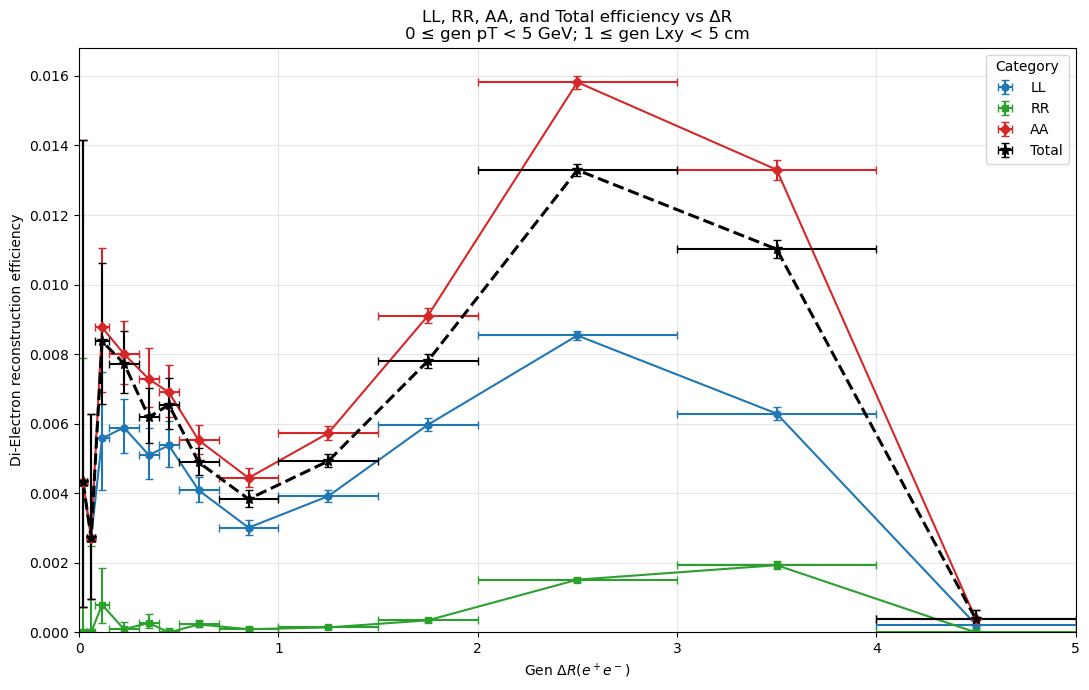

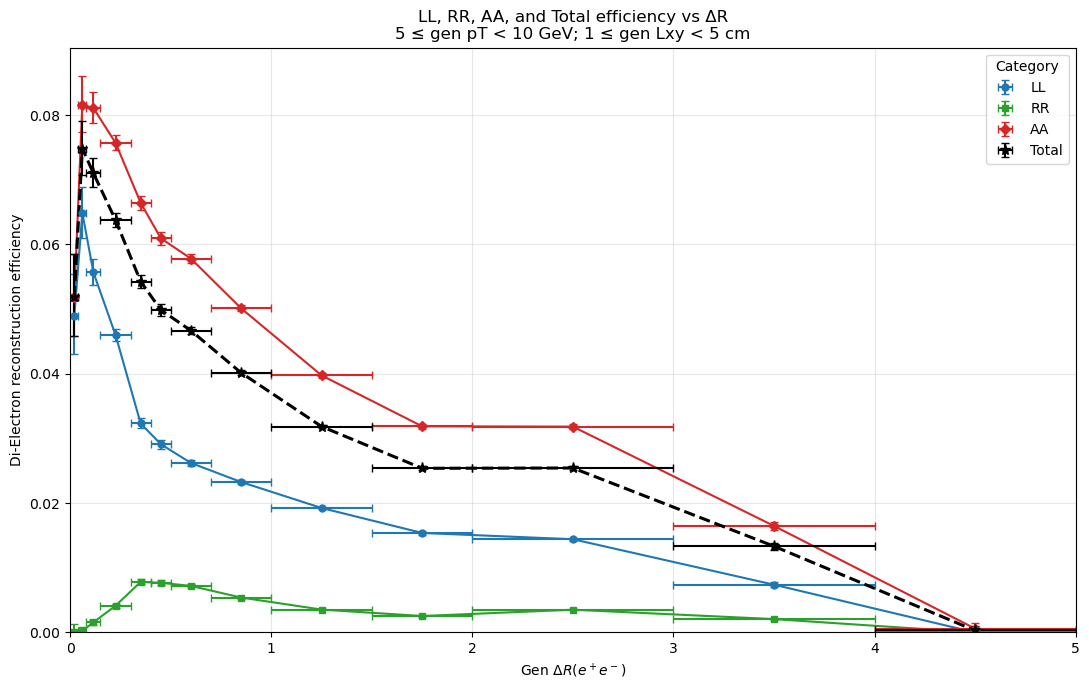

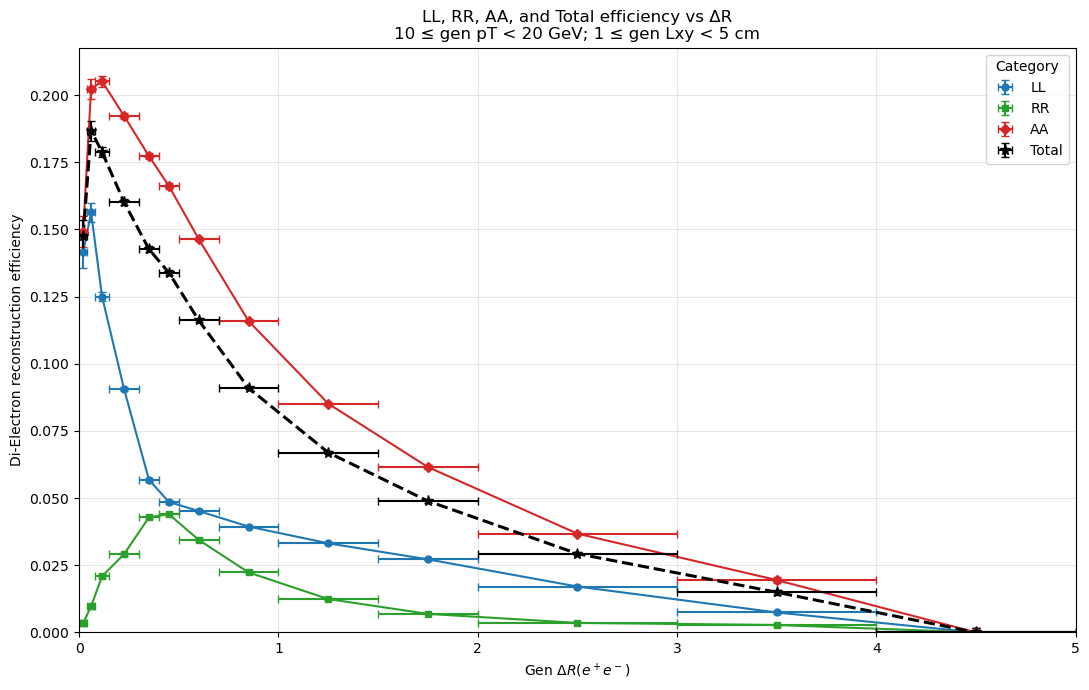

In [5]:
figures_by_region = {}
for region_key in regions:
    curves = region_results[region_key]["curves"]
    x = (dr_edges[:-1] + dr_edges[1:]) / 2
    xerr = np.vstack((x - dr_edges[:-1], dr_edges[1:] - x))

    colours = {'LL': 'tab:blue', 'RR': 'tab:green', 'LR': 'tab:orange',
               'AA': 'tab:red', 'Total': 'black'}

    markers = {
        'LL': 'o',
        'RR': 's',
        'LR': '^',
        'AA': 'D',
        'Total': '*',
    }

    fig, ax = plt.subplots(figsize=(11, 7))

    # Preserve the source plot's LL/RR/AA curves and add Total.
    # Add 'LR' here if you also want its individual curve.
    plot_categories = ('LL', 'RR', 'AA', 'Total')
    for category in plot_categories:
        efficiency = curves[category]['efficiency']
        uncertainty = curves[category]['uncertainty']
        finite = np.isfinite(efficiency)

        ax.plot(
            x, efficiency,
            color=colours[category],
            linewidth=2.2 if category == 'Total' else 1.5,
            linestyle='--' if category == 'Total' else '-',
        )

        ax.errorbar(
            x[finite],
            efficiency[finite],
            xerr=xerr[:, finite],
            yerr=uncertainty[:, finite],
            fmt=markers[category],
            color=colours[category],
            markersize=8 if category == 'Total' else 5,
            capsize=3,
            label=category,
        )

    ax.set_xlim(dr_edges[0], dr_edges[-1])
    # Optional small-ΔR view: use ax.set_xlim(0, 0.2).
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'Gen $\Delta R(e^+e^-)$')
    ax.set_ylabel('Di-Electron reconstruction efficiency')

    pt_low, pt_high = regions[region_key]['pt']
    lxy_low, lxy_high = regions[region_key]['lxy']
    ax.set_title(
        f'LL, RR, AA, and Total efficiency vs ΔR\n'
        f'{pt_low:g} ≤ gen pT < {pt_high:g} GeV; '
        f'{lxy_low:g} ≤ gen Lxy < {lxy_high:g} cm'
    )
    ax.grid(alpha=0.3)
    ax.legend(title='Category')

    fig.tight_layout()
    figures_by_region[region_key] = fig
    plt.show()
    plt.close(fig)


## Optional: save both figures
Run the next cell only to save PNG/PDF files on LPC. Each filename identifies the pT and Lxy selection. No files are overwritten.


In [6]:
from datetime import datetime
output_parent = LPC_REPO / 'python_analysis/plots/VertexRecEff_vs_dR_pt_lxy_bins'
output_parent.mkdir(parents=True, exist_ok=True)
output_dir = output_parent / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
output_dir.mkdir(exist_ok=False)
for region_key, figure in figures_by_region.items():
    for extension in ('png', 'pdf'):
        destination = output_dir / f'LL_RR_AA_Total_efficiency_vs_dR_{region_key}.{extension}'
        with destination.open('xb') as stream:
            figure.savefig(stream, format=extension, dpi=300, bbox_inches='tight', facecolor='white')
        print('Saved:', destination)


Saved: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/plots/VertexRecEff_vs_dR_pt_lxy_bins/20261021_143746_935683/LL_RR_AA_Total_efficiency_vs_dR_pt0to5_lxy1to5.png
Saved: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/plots/VertexRecEff_vs_dR_pt_lxy_bins/20261021_143746_935683/LL_RR_AA_Total_efficiency_vs_dR_pt0to5_lxy1to5.pdf
Saved: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/plots/VertexRecEff_vs_dR_pt_lxy_bins/20261021_143746_935683/LL_RR_AA_Total_efficiency_vs_dR_pt5to10_lxy1to5.png
Saved: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/plots/VertexRecEff_vs_dR_pt_lxy_bins/20261021_143746_935683/LL_RR_AA_Total_efficiency_vs_dR_pt5to10_lxy1to5.pdf
Saved: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/plots/VertexRecEff_vs_dR_pt_lxy_bins/20261021_143746_935683/LL_RR_AA_Total_efficiency_vs_dR_pt